# Assignment 4, Task 2: Evaluating Reweighing (Kamiran & Calders, 2012)

This notebook evaluates the **Reweighing** pre-processing algorithm from AIF360 on three public datasets: **Adult**, **German Credit** and **COMPAS**.

Pipeline, following the assignment:
1. Load each dataset and compute **DP_Diff**, **DIR** and **consistency** on the original labels (before any mitigation or model).
2. Make a **stratified** 70/30 train/test split.
3. Fit Reweighing on the **training data only**, which gives one weight per training example.
4. Train a logistic regression classifier with these weights (and a baseline without weights for comparison).
5. On the held-out test set, report DP_Diff, DIR, consistency, accuracy and balanced accuracy of the final predictions.
6. Compare the fairness measures before and after mitigation.

Main results use one split (seed 42). Section 6 repeats the whole pipeline with 10 different seeds to check that the conclusions are stable.

## 0. Setup

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)   # hide AIF360 "missing data removed" messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, aif360

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from aif360.datasets import AdultDataset, GermanDataset, CompasDataset
from aif360.metrics import BinaryLabelDatasetMetric
from aif360.algorithms.preprocessing import Reweighing

pd.set_option("display.precision", 3)
import os
os.makedirs("results", exist_ok=True)
print("aif360", aif360.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

aif360 0.6.1 | sklearn 1.7.2 | pandas 2.3.3 | numpy 2.3.5


## 1. Parameter settings

| Setting | Value |
|---|---|
| Protected attribute (Adult) | `sex`; privileged = Male (1), unprivileged = Female (0) |
| Protected attribute (German) | `age`; privileged = older than 25 (1), unprivileged = 25 or younger (0) |
| Protected attribute (COMPAS) | `race`; privileged = Caucasian (1), unprivileged = not Caucasian (0) |
| Favourable label | Adult: income > 50K; German: good credit; COMPAS: no re-offence in two years |
| Train/test split | 70% / 30%, stratified on label **and** protected group together |
| Random seed | 42 (main run), seeds 0-9 (robustness check) |
| Classifier | `LogisticRegression(max_iter=1000, solver="lbfgs")` on standardised features |
| Decision threshold | 0.5 (default `predict`) |
| Reweighing | `Reweighing(unprivileged_groups, privileged_groups)`, fitted on training data only; weights passed as `sample_weight` |
| Consistency | k = 5 nearest neighbours (Euclidean), on standardised features (scaler fitted on training data), labels coded 1 = favourable |

Definitions used (all from AIF360):
- **DP_Diff** = P(favourable | unprivileged) - P(favourable | privileged). Fair value is 0; negative means the unprivileged group gets fewer favourable outcomes.
- **DIR** = P(favourable | unprivileged) / P(favourable | privileged). Fair value is 1; the usual "80% rule" flags values below 0.8.
- **Sign convention:** the Reweighing paper measures discrimination as P(+ | favoured) - P(+ | deprived), which is the same number as our DP_Diff but with the **opposite sign**. So a paper discrimination of 0.19 corresponds to DP_Diff = -0.19 here.
- **Consistency** = 1 - mean |label of x - mean label of its 5 nearest neighbours|. Value 1 means similar people get the same label (individual fairness).

In [2]:
SEED = 42
TEST_SIZE = 0.3
K_NEIGHBOURS = 5

def load_datasets():
    """Returns {name: (dataset, protected attribute)}. The datasets keep only one protected attribute."""
    return {
        "Adult":  (AdultDataset(protected_attribute_names=["sex"],
                                privileged_classes=[["Male"]],
                                categorical_features=["workclass", "education", "marital-status", "occupation",
                                                      "relationship", "native-country", "race"],
                                features_to_drop=["fnlwgt"]), "sex"),
        "German": (GermanDataset(protected_attribute_names=["age"],
                                 privileged_classes=[lambda x: x > 25],
                                 features_to_drop=["personal_status", "sex"]), "age"),
        "COMPAS": (CompasDataset(protected_attribute_names=["race"],
                                 privileged_classes=[["Caucasian"]],
                                 features_to_drop=["sex"]), "race"),
    }

DATA = load_datasets()
for name, (ds, attr) in DATA.items():
    print(f"{name:7s} rows={ds.features.shape[0]:6d} features={ds.features.shape[1]:4d} protected={attr} "
          f"favourable_label={ds.favorable_label}")

Adult   rows= 45222 features= 102 protected=sex favourable_label=1.0
German  rows=  1000 features=  57 protected=age favourable_label=1.0
COMPAS  rows=  6167 features= 400 protected=race favourable_label=0.0


**Note on `features_to_drop`.** In German, `sex` is coded inside `personal_status`, so both are dropped to keep only `age` as the protected attribute. In COMPAS, `sex` is dropped for the same reason. `fnlwgt` in Adult is a census sampling weight and not a property of the person, so it is dropped too. In Adult, `race` is no longer a protected attribute here, so it is one-hot encoded like the other categorical features. The protected attribute itself stays in the features (AIF360 default), because Reweighing does not need it removed.

## 2. Helper functions

In [3]:
def groups(attr):
    return [{attr: 0}], [{attr: 1}]   # unprivileged, privileged

def scaled_copy(ds, scaler):
    """Copy of an AIF360 dataset with standardised features (used for consistency only)."""
    c = ds.copy(deepcopy=True)
    c.features = scaler.transform(ds.features)
    return c

def consistency(X, y, k=K_NEIGHBOURS):
    """Same formula as AIF360's BinaryLabelDatasetMetric.consistency (k neighbours, point itself included),
    but vectorised with a brute-force kNN, because AIF360's ball-tree + Python loop is very slow on Adult/COMPAS."""
    y = np.asarray(y, dtype=float).ravel()
    _, idx = NearestNeighbors(n_neighbors=k, algorithm="brute", n_jobs=-1).fit(X).kneighbors(X)
    return 1.0 - np.mean(np.abs(y - y[idx].mean(axis=1)))

def fairness_metrics(ds, attr, scaler):
    """DP_Diff, DIR and consistency of the labels stored in `ds`."""
    unpriv, priv = groups(attr)
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=unpriv, privileged_groups=priv)
    y01 = (ds.labels.ravel() == ds.favorable_label).astype(float)   # 1 = favourable, 0 = unfavourable
    return {
        "DP_Diff": m.statistical_parity_difference(),
        "DIR": m.disparate_impact(),
        "Consistency": consistency(scaler.transform(ds.features), y01),
        "P(fav|unpriv)": m.num_positives(privileged=False) / m.num_instances(privileged=False),
        "P(fav|priv)": m.num_positives(privileged=True) / m.num_instances(privileged=True),
    }

def stratified_split(ds, attr, seed):
    """70/30 split, stratified on (label, protected group) so both keep their proportions."""
    idx = np.arange(ds.features.shape[0])
    a = ds.protected_attributes[:, ds.protected_attribute_names.index(attr)]
    strata = ds.labels.ravel().astype(int).astype(str) + "_" + a.astype(int).astype(str)
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=strata, random_state=seed)
    return ds.subset(tr), ds.subset(te)

def train_and_predict(train, test, weights):
    """Logistic regression on standardised features; returns test dataset with predicted labels."""
    scaler = StandardScaler().fit(train.features)
    clf = LogisticRegression(max_iter=1000, solver="lbfgs")
    clf.fit(scaler.transform(train.features), train.labels.ravel(), sample_weight=weights)
    pred = test.copy(deepcopy=True)
    pred.labels = clf.predict(scaler.transform(test.features)).reshape(-1, 1)
    return pred, clf

def performance(test, pred):
    y, p = test.labels.ravel(), pred.labels.ravel()
    return {"Accuracy": accuracy_score(y, p), "Balanced acc.": balanced_accuracy_score(y, p)}

**Check:** our fast consistency gives the same value as AIF360's own implementation (tested on German, which is small enough for AIF360's slow version).

In [4]:
ds_g, attr_g = DATA["German"]
sc_g = StandardScaler().fit(ds_g.features)
ds_g01 = scaled_copy(ds_g, sc_g)
ds_g01.labels = (ds_g.labels == ds_g.favorable_label).astype(float)
aif = float(BinaryLabelDatasetMetric(ds_g01, unprivileged_groups=groups(attr_g)[0], privileged_groups=groups(attr_g)[1]).consistency(n_neighbors=K_NEIGHBOURS)[0])
ours = consistency(sc_g.transform(ds_g.features), ds_g01.labels)
print(f"AIF360: {aif:.6f}   ours: {ours:.6f}   equal: {np.isclose(aif, ours)}")

AIF360: 0.738200   ours: 0.738200   equal: True


## 3. Step 1: fairness of the original labels (before mitigation and before any classifier)

Computed on the **full** dataset, using the true labels.

In [5]:
orig_rows = []
for name, (ds, attr) in DATA.items():
    scaler_full = StandardScaler().fit(ds.features)
    r = fairness_metrics(ds, attr, scaler_full)
    orig_rows.append({"Dataset": name, "n": ds.features.shape[0], **r})
original = pd.DataFrame(orig_rows).set_index("Dataset")
original

,n,DP_Diff,DIR,Consistency,P(fav|unpriv),P(fav|priv)
Dataset,,,,,,
Adult,45222,-0.199,0.363,0.828,0.114,0.312
German,1000,-0.149,0.795,0.738,0.579,0.728
COMPAS,6167,-0.097,0.840,0.670,0.511,0.609


## 4. Steps 2-5: stratified split, Reweighing, training and test evaluation

For each dataset we compute four rows:
- **Test labels**: the true labels of the test set (reference point).
- **Train labels, reweighed**: the weighted training data after Reweighing. This only checks that the algorithm does what it promises (weighted DP_Diff should become 0).
- **Baseline LR**: logistic regression without weights, test predictions.
- **Reweighing + LR**: logistic regression trained with Reweighing weights, test predictions. This is the final mitigated pipeline.

In [6]:
def run_pipeline(ds, attr, seed, verbose=False):
    unpriv, priv = groups(attr)
    train, test = stratified_split(ds, attr, seed)
    scaler = StandardScaler().fit(train.features)        # for consistency, fitted on train only

    # Reweighing: fit on training data only, then transform it (only instance_weights change)
    rw = Reweighing(unprivileged_groups=unpriv, privileged_groups=priv)
    train_rw = rw.fit_transform(train)

    base_pred, _ = train_and_predict(train, test, weights=None)
    rw_pred, _   = train_and_predict(train_rw, test, weights=train_rw.instance_weights)

    rows = {
        "Test labels":             {**fairness_metrics(test, attr, scaler)},
        "Train labels, reweighed": {**fairness_metrics(train_rw, attr, scaler)},
        "Baseline LR":             {**fairness_metrics(base_pred, attr, scaler), **performance(test, base_pred)},
        "Reweighing + LR":         {**fairness_metrics(rw_pred, attr, scaler), **performance(test, rw_pred)},
    }
    if verbose:
        # the four weights Reweighing assigns: (group, label) -> weight
        a = train.protected_attributes[:, train.protected_attribute_names.index(attr)]
        w = pd.DataFrame({"group": np.where(a == 1, "privileged", "unprivileged"),
                          "label": np.where(train.labels.ravel() == train.favorable_label, "favourable", "unfavourable"),
                          "weight": train_rw.instance_weights})
        print(w.groupby(["group", "label"])["weight"].agg(["first", "count"]).rename(columns={"first": "weight"}))
    return pd.DataFrame(rows).T

results = {}
for name, (ds, attr) in DATA.items():
    print(f"\n=== {name} (protected: {attr}) — Reweighing weights per (group, label) ===")
    results[name] = run_pipeline(ds, attr, SEED, verbose=True)


=== Adult (protected: sex) — Reweighing weights per (group, label) ===


                           weight  count
group        label                      
privileged   favourable     0.793   6677
             unfavourable   1.094  14692
unprivileged favourable     2.183   1168
             unfavourable   0.849   9118

=== German (protected: age) — Reweighing weights per (group, label) ===
                           weight  count
group        label                      
privileged   favourable     0.961    413
             unfavourable   1.105    154
unprivileged favourable     1.209     77
             unfavourable   0.713     56

=== COMPAS (protected: race) — Reweighing weights per (group, label) ===


                           weight  count
group        label                      
privileged   favourable     0.895    894
             unfavourable   1.164    575
unprivileged favourable     1.065   1456
             unfavourable   0.932   1391


In [7]:
cols = ["DP_Diff", "DIR", "Consistency", "Accuracy", "Balanced acc."]
for name, df in results.items():
    print(f"\n=== {name} ===")
    display(df[cols].round(3))


=== Adult ===


,DP_Diff,DIR,Consistency,Accuracy,Balanced acc.
Test labels,-0.199,0.364,0.824,NaN,NaN
"Train labels, reweighed",-0.000,1.000,0.826,NaN,NaN
Baseline LR,-0.184,0.304,0.941,0.851,0.771
Reweighing + LR,-0.092,0.572,0.946,0.846,0.751



=== German ===


,DP_Diff,DIR,Consistency,Accuracy,Balanced acc.
Test labels,-0.149,0.795,0.744,NaN,NaN
"Train labels, reweighed",-0.000,1.000,0.720,NaN,NaN
Baseline LR,-0.222,0.711,0.813,0.770,0.715
Reweighing + LR,-0.069,0.909,0.815,0.747,0.679



=== COMPAS ===


,DP_Diff,DIR,Consistency,Accuracy,Balanced acc.
Test labels,-0.097,0.840,0.654,NaN,NaN
"Train labels, reweighed",0.000,1.000,0.669,NaN,NaN
Baseline LR,-0.144,0.797,0.859,0.661,0.652
Reweighing + LR,0.012,1.021,0.853,0.648,0.640


## 5. Step 6: before vs. after comparison (seed 42)

In [8]:
summary = []
for name in DATA:
    o, r = original.loc[name], results[name]
    summary.append({
        "Dataset": name,
        "DP_Diff original": o["DP_Diff"], "DP_Diff baseline": r.loc["Baseline LR", "DP_Diff"], "DP_Diff reweighed": r.loc["Reweighing + LR", "DP_Diff"],
        "DIR original": o["DIR"], "DIR baseline": r.loc["Baseline LR", "DIR"], "DIR reweighed": r.loc["Reweighing + LR", "DIR"],
        "Cons. original": o["Consistency"], "Cons. baseline": r.loc["Baseline LR", "Consistency"], "Cons. reweighed": r.loc["Reweighing + LR", "Consistency"],
        "Acc. baseline": r.loc["Baseline LR", "Accuracy"], "Acc. reweighed": r.loc["Reweighing + LR", "Accuracy"],
        "Bal. acc. baseline": r.loc["Baseline LR", "Balanced acc."], "Bal. acc. reweighed": r.loc["Reweighing + LR", "Balanced acc."],
    })
summary = pd.DataFrame(summary).set_index("Dataset")
summary.T.round(3)

Dataset,Adult,German,COMPAS
DP_Diff original,-0.199,-0.149,-0.097
DP_Diff baseline,-0.184,-0.222,-0.144
DP_Diff reweighed,-0.092,-0.069,0.012
DIR original,0.363,0.795,0.840
DIR baseline,0.304,0.711,0.797
DIR reweighed,0.572,0.909,1.021
Cons. original,0.828,0.738,0.670
Cons. baseline,0.941,0.813,0.859
Cons. reweighed,0.946,0.815,0.853
Acc. baseline,0.851,0.770,0.661


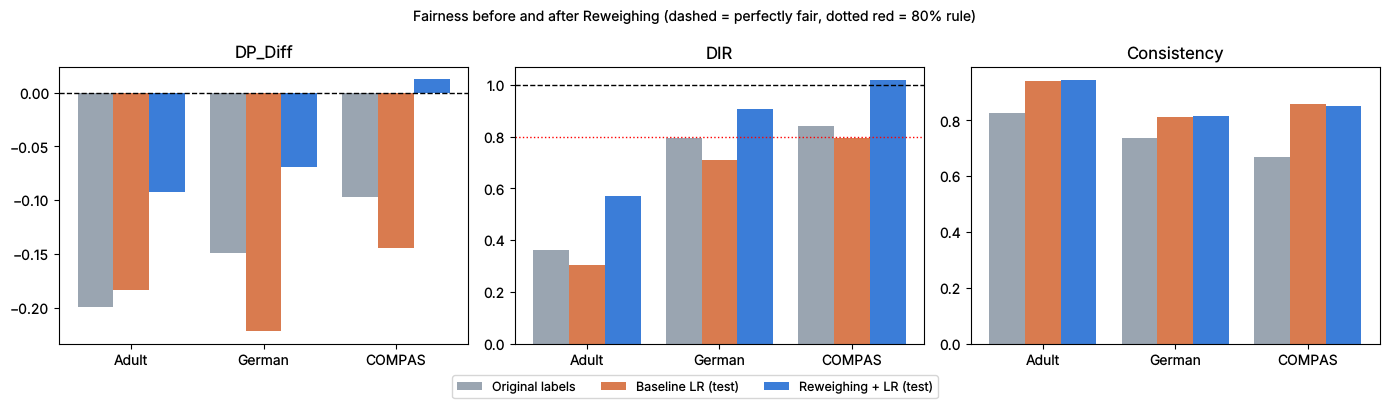

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
stages = ["Original labels", "Baseline LR (test)", "Reweighing + LR (test)"]
colors = ["#9aa5b1", "#d97b4f", "#3b7dd8"]
for ax, (metric, key, ideal) in zip(axes, [("DP_Diff", "DP_Diff", 0), ("DIR", "DIR", 1), ("Consistency", "Cons.", None)]):
    x = np.arange(len(DATA))
    for i, (stage, col) in enumerate(zip(stages, [f"{key} original", f"{key} baseline", f"{key} reweighed"])):
        ax.bar(x + (i - 1) * 0.27, summary[col], width=0.27, label=stage, color=colors[i])
    if ideal is not None:
        ax.axhline(ideal, color="black", lw=1, ls="--")
    if metric == "DIR":
        ax.axhline(0.8, color="red", lw=1, ls=":")
    ax.set_xticks(x); ax.set_xticklabels(list(DATA)); ax.set_title(metric)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.suptitle("Fairness before and after Reweighing (dashed = perfectly fair, dotted red = 80% rule)", fontsize=10)
plt.tight_layout()
plt.savefig("results/fairness_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Robustness check: 10 random splits

One split can be lucky or unlucky, especially for German (only 300 test rows). Here the whole pipeline is repeated with seeds 0-9 and we report mean ± standard deviation of the test-set results.

In [10]:
rep = []
for name, (ds, attr) in DATA.items():
    for seed in range(10):
        r = run_pipeline(ds, attr, seed)
        for model in ["Baseline LR", "Reweighing + LR"]:
            rep.append({"Dataset": name, "Model": model, "seed": seed, **r.loc[model, cols].to_dict()})
rep = pd.DataFrame(rep)
agg = rep.groupby(["Dataset", "Model"])[cols].agg(["mean", "std"])
agg.round(3)

DP_Diff           DIR        Consistency         \
                           mean    std   mean    std        mean    std   
Dataset Model                                                             
Adult   Baseline LR      -0.186  0.005  0.293  0.012       0.942  0.001   
        Reweighing + LR  -0.087  0.005  0.598  0.017       0.944  0.001   
COMPAS  Baseline LR      -0.162  0.030  0.777  0.036       0.863  0.004   
        Reweighing + LR  -0.002  0.027  0.998  0.042       0.861  0.003   
German  Baseline LR      -0.238  0.069  0.702  0.079       0.812  0.009   
        Reweighing + LR  -0.070  0.055  0.910  0.070       0.816  0.014   

                        Accuracy        Balanced acc.         
                            mean    std          mean    std  
Dataset Model                                                 
Adult   Baseline LR        0.849  0.003         0.766  0.004  
        Reweighing + LR    0.843  0.002         0.748  0.004  
COMPAS  Baseline LR        0.668  0.008         0.659  0.008  
        Reweighing + LR    0.663  0.009         0.654  0.009  
German  Baseline LR        0.743  0.020         0.670  0.023  
        Reweighing + LR    0.743  0.025         0.667  0.025

In [11]:
# compact "mean ± std" table, used in the report
fmt = rep.groupby(["Dataset", "Model"])[cols].agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")
fmt

DP_Diff            DIR    Consistency  \
Dataset Model                                                           
Adult   Baseline LR      -0.186 ± 0.005  0.293 ± 0.012  0.942 ± 0.001   
        Reweighing + LR  -0.087 ± 0.005  0.598 ± 0.017  0.944 ± 0.001   
COMPAS  Baseline LR      -0.162 ± 0.030  0.777 ± 0.036  0.863 ± 0.004   
        Reweighing + LR  -0.002 ± 0.027  0.998 ± 0.042  0.861 ± 0.003   
German  Baseline LR      -0.238 ± 0.069  0.702 ± 0.079  0.812 ± 0.009   
        Reweighing + LR  -0.070 ± 0.055  0.910 ± 0.070  0.816 ± 0.014   

                              Accuracy  Balanced acc.  
Dataset Model                                          
Adult   Baseline LR      0.849 ± 0.003  0.766 ± 0.004  
        Reweighing + LR  0.843 ± 0.002  0.748 ± 0.004  
COMPAS  Baseline LR      0.668 ± 0.008  0.659 ± 0.008  
        Reweighing + LR  0.663 ± 0.009  0.654 ± 0.009  
German  Baseline LR      0.743 ± 0.020  0.670 ± 0.023  
        Reweighing + LR  0.743 ± 0.025  0.667 ± 0.025

## 7. Save results

In [12]:
import os
os.makedirs("results", exist_ok=True)
original.to_csv("results/original_label_metrics.csv")
pd.concat(results, names=["Dataset", "Row"]).to_csv("results/seed42_results.csv")
summary.to_csv("results/before_after_summary.csv")
rep.to_csv("results/repeated_10_seeds_raw.csv", index=False)
fmt.to_csv("results/repeated_10_seeds_mean_std.csv")
print(sorted(os.listdir("results")))

['before_after_summary.csv', 'fairness_before_after.png', 'original_label_metrics.csv', 'repeated_10_seeds_mean_std.csv', 'repeated_10_seeds_raw.csv', 'seed42_results.csv']


## 8. Short interpretation

- The **original labels** of all three datasets favour the privileged group (DP_Diff < 0, DIR < 1). Adult (sex) is by far the most biased (DIR 0.36); German (age) is just under the 80% rule and COMPAS (race) just above it.
- The **baseline** classifier does not remove this bias. On German and COMPAS it even makes it larger than in the labels, and on Adult the DIR drops further.
- **Reweighing** makes the weighted training data perfectly balanced (DP_Diff = 0, DIR = 1), as the paper promises. The classifier trained with these weights roughly halves DP_Diff on Adult and moves German and COMPAS close to the fair values on the test set.
- On Adult the DIR is still below 0.8 after Reweighing, because other features (for example `relationship` = Husband/Wife and `marital-status`) carry a lot of information about sex, and the classifier can still use them.
- The accuracy cost is small (0 to 0.6 percentage points over 10 seeds), and consistency of the predictions stays almost the same, so individual fairness is not harmed.
- The robustness check over 10 seeds gives the same picture; German has the largest standard deviation because its test set has only 300 rows.